# 05 — Apprentissage non supervisé : zones climatiques exploratoires

> Exécutez les cellules dans l'ordre. Les résultats sont régénérés à partir des données brutes ; les notebooks ne dépendent pas des anciens fichiers de sortie.

## Objectif du regroupement et unité d'analyse
Nous regroupons les **sites de la grille** selon leur empreinte climatique mensuelle : moyennes mensuelles du climat sur toute la période source. Nous n'ajoutons pas les coordonnées aux caractéristiques, afin que les groupes soient déterminés par les attributs climatiques et non seulement par la proximité des sites. L'analyse est descriptive sur toute la période 2015–2026 ; ce n'est pas un test prédictif, et ne produit pas une délimitation officielle des régions climatiques.

In [ ]:
from pathlib import Path
import sys

# Locate the project whether Jupyter was started in the project root or notebooks/.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
PROJECT_ROOT = next((p for p in _candidates if (p / "data" / "raw" / "era5_algeria_raw.nc").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter from the project root or notebooks/ folder.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from climate_utils import (
    load_masked_dataset, make_algeria_mask, load_boundary,
    regional_time_series, to_analysis_units, area_weighted_mean,
)

plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42
print("Project root:", PROJECT_ROOT)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

raw_ds, polygon_mask, geometry = load_masked_dataset(PROJECT_ROOT)
valid_mask = polygon_mask & ~raw_ds["t2m"].isnull().all("valid_time")
print("Nombre de sites climatiques valides:", int(valid_mask.sum().values))

Project root: /home/ubuntu/work/climate_project/Climate_Data_Mining12345/Climate_Data_Mining


عدد المواقع المناخية الصالحة: 21245


## Création de caractéristiques saisonnières pour chaque site
Nous utilisons les températures de l'air et du point de rosée mensuelles (°C), les précipitations (mm par enregistrement source), et la vitesse du vent. Chaque site devient un enregistrement avec des caractéristiques mensuelles ; comme `t2m_month_01` à `t2m_month_12`. Cela préserve la forme de la saisonnalité au lieu de réduire toute l'année à une seule moyenne.

In [ ]:
climate_variables = {
    "t2m_c": raw_ds["t2m"] - 273.15,
    "d2m_c": raw_ds["d2m"] - 273.15,
    "tp_mm": raw_ds["tp"] * 1000.0,
    "wind10_speed": np.hypot(raw_ds["u10"], raw_ds["v10"]),
}
flat_mask = valid_mask.values.ravel()
lat2d, lon2d = np.meshgrid(raw_ds["longitude"].values, raw_ds["latitude"].values)
feature_columns = {}
for name, da in climate_variables.items():
    month_means = da.where(valid_mask).groupby("valid_time.month").mean("valid_time", skipna=True)
    for m in range(1, 13):
        values = month_means.sel(month=m).values.ravel()[flat_mask]
        feature_columns[f"{name}_month_{m:02d}"] = values
feature_frame = pd.DataFrame(feature_columns)
feature_frame["latitude"] = lat2d.ravel()[flat_mask]
feature_frame["longitude"] = lon2d.ravel()[flat_mask]
print("Matrice de caractéristiques:", feature_frame.shape)
print("Valeurs manquantes avant imputation:", int(feature_frame.drop(columns=["latitude", "longitude"]).isna().sum().sum()))
display(feature_frame.head())

مصفوفة الخصائص: (21245, 50)
القيم المفقودة قبل التعويض: 0


,t2m_c_month_01,t2m_c_month_02,t2m_c_month_03,t2m_c_month_04,t2m_c_month_05,t2m_c_month_06,t2m_c_month_07,t2m_c_month_08,t2m_c_month_09,t2m_c_month_10,...,wind10_speed_month_05,wind10_speed_month_06,wind10_speed_month_07,wind10_speed_month_08,wind10_speed_month_09,wind10_speed_month_10,wind10_speed_month_11,wind10_speed_month_12,latitude,longitude
0,10.548839,11.150380,12.511180,14.830170,18.031870,22.770782,26.280283,26.315744,23.466400,19.709070,...,0.579627,0.751557,1.047881,1.012401,0.654418,0.741725,1.967718,1.847063,6.3,37.0
1,9.995616,10.603668,11.976186,14.345958,17.571585,22.380157,25.932302,25.991852,23.112885,19.253283,...,0.605325,0.687473,0.936489,0.907481,0.634790,0.757902,1.940962,1.838298,6.4,37.0
2,10.779469,11.322255,12.661896,14.886322,18.061493,22.724884,26.205740,26.362295,23.660248,19.942558,...,0.691637,0.703913,0.922816,0.902619,0.664890,0.781309,1.968328,1.874940,6.5,37.0
3,11.476247,12.068024,13.513133,15.768321,19.026499,23.935659,27.399912,27.390127,24.687754,20.977715,...,1.121096,1.117342,1.220388,1.100791,0.917722,0.835858,1.765715,1.677780,7.4,37.0
4,11.215179,11.841624,13.310496,15.640880,18.946096,23.905060,27.389170,27.328766,24.552826,20.803709,...,1.140133,1.134460,1.247861,1.124457,0.935885,0.837423,1.767358,1.694652,7.5,37.0


## Traitement du manque et normalisation
Comme K-means dépend des distances, nous normalisons les caractéristiques pour éviter que les précipitations ou toute plage numérique plus grande ne dominent. Si quelques valeurs restent manquantes dans des sites valides, nous utilisons la médiane de la caractéristique uniquement pour ce regroupement descriptif. Ces valeurs imputées ne sont pas utilisées dans le notebook de prévision.

In [ ]:
climate_cols = [c for c in feature_frame.columns if c not in ("latitude", "longitude")]
X_climate = feature_frame[climate_cols].to_numpy()
imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_imputed = imputer.fit_transform(X_climate)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
print("Étendue de la moyenne après normalisation:", np.round(X_scaled.mean(axis=0)[:4], 3))

نطاق المتوسط بعد التقييس: [-0.  0.  0. -0.]


## Choix du nombre de groupes et examen
Nous testons de petites valeurs de K et utilisons le silhouette sur un échantillon fixe pour estimer la cohésion et la séparation, et non comme preuve finale de l'existence de régions naturelles. Le voisinage spatial est corrélé, donc le score de silhouette peut être optimiste. Nous examinons également les profils climatiques et les cartes.

,k,sample_silhouette
0,2,0.539
1,3,0.276
2,4,0.292
3,5,0.330
4,6,0.316


/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1577 (\N{ARABIC LETTER TEH MARBUTA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1606 (\N{ARABIC LETTER NOON}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1610 (\N{ARABIC LETTER YEH}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1593 (\N{ARABIC LETTER AIN}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1604 (\N{ARABIC LETTER LAM}) missing from font(s) Liber

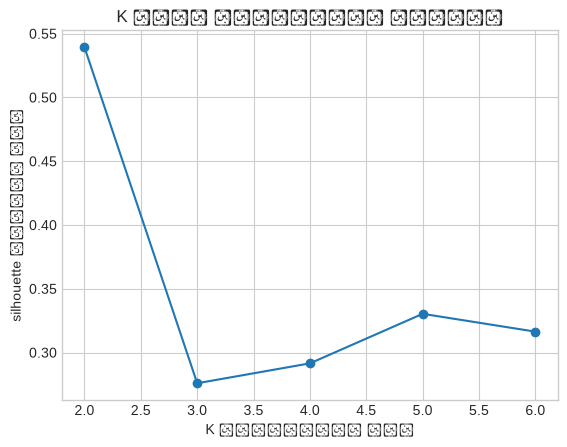

K المختار استكشافيًا: 2


In [ ]:
sample_size = min(2500, len(X_scaled))
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = np.sort(rng.choice(len(X_scaled), size=sample_size, replace=False))
scores = []
for k in range(2, 7):
    candidate = MiniBatchKMeans(n_clusters=k, random_state=RANDOM_STATE, batch_size=512, n_init=5)
    sample_labels = candidate.fit_predict(X_scaled[sample_idx])
    score = silhouette_score(X_scaled[sample_idx], sample_labels)
    scores.append({"k": k, "sample_silhouette": score})
scores = pd.DataFrame(scores)
display(scores.round(3))
plt.plot(scores["k"], scores["sample_silhouette"], marker="o")
plt.xlabel("Nombre de groupes K"); plt.ylabel("silhouette sur l'échantillon"); plt.title("Comparaison exploratoire des valeurs K"); plt.show()
chosen_k = int(scores.loc[scores["sample_silhouette"].idxmax(), "k"])
print("K choisi de manière exploratoire:", chosen_k)

## Regroupement de tous les sites et visualisation ACP
Nous ajustons MiniBatchKMeans sur tous les sites valides. Nous utilisons l'ACP bidimensionnelle uniquement pour le dessin ; le regroupement a été effectué sur toutes les caractéristiques climatiques normalisées, et non sur la projection ACP. La proximité de deux points dans le dessin ne suffit pas à confirmer la similarité climatique.

التباين الذي يعرضه أول مكونين: 0.728


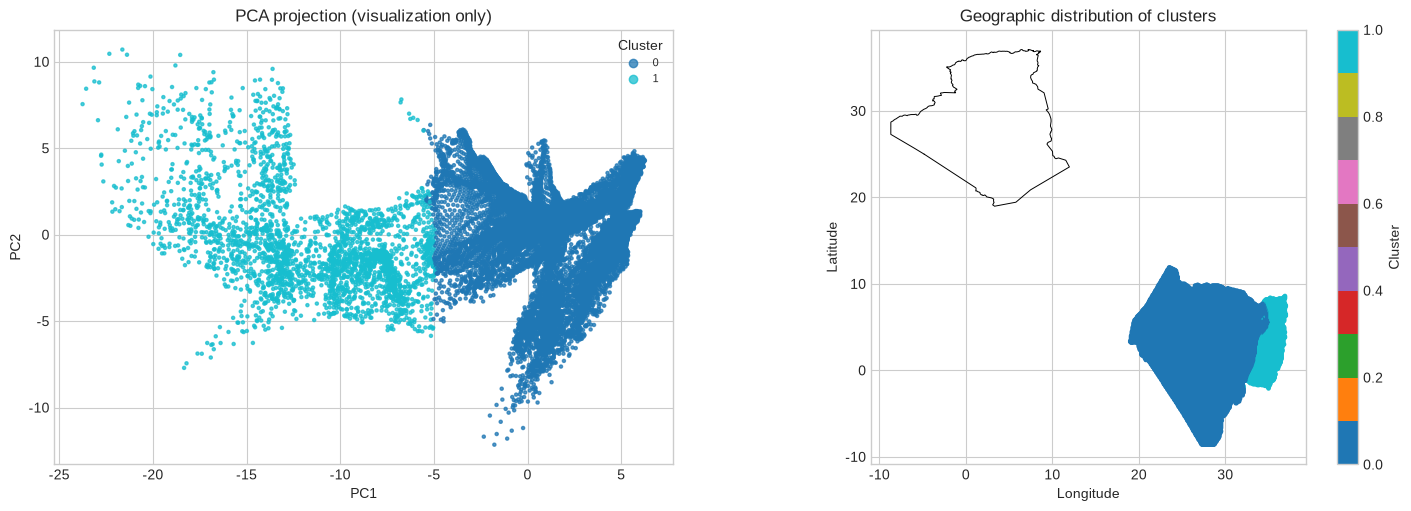

In [ ]:
cluster_model = MiniBatchKMeans(n_clusters=chosen_k, random_state=RANDOM_STATE, batch_size=1024, n_init=10)
labels = cluster_model.fit_predict(X_scaled)
feature_frame["cluster"] = labels
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
embedding = pca_2d.fit_transform(X_scaled)
print("Variance expliquée par les deux premiers composants:", round(float(pca_2d.explained_variance_ratio_.sum()), 3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
sc = axes[0].scatter(embedding[:, 0], embedding[:, 1], c=labels, s=5, cmap="tab10", alpha=.75)
axes[0].set(title="Projection ACP (visualisation uniquement)", xlabel="PC1", ylabel="PC2")
axes[0].legend(*sc.legend_elements(), title="Cluster", loc="best", fontsize=8)
sc2 = axes[1].scatter(feature_frame["longitude"], feature_frame["latitude"], c=labels, s=5, cmap="tab10")
for geom in getattr(geometry, "geoms", [geometry]):
    x, y = geom.exterior.xy
    axes[1].plot(x, y, color="black", linewidth=.7)
axes[1].set(title="Distribution géographique des clusters", xlabel="Longitude", ylabel="Latitude", aspect="equal")
fig.colorbar(sc2, ax=axes[1], label="Cluster")
plt.show()

## Interprétation des profils de clusters
Nous comparons la moyenne annuelle et l'étendue saisonnière de la température, et la moyenne des enregistrements de précipitations mensuels dans chaque groupe. Ce sont des descriptions pour aider l'interprétation ; des noms comme "désertique" ou "côtier" nécessitent un examen géographique et contextuel supplémentaire et ne sont pas donnés automatiquement.

,mean_annual_t2m_C,seasonal_t2m_range_C,mean_monthly_tp_mm,number_of_grid_cells
cluster,,,,
0,24.809999,22.690001,0.07,18444
1,17.129999,21.780001,0.84,2801


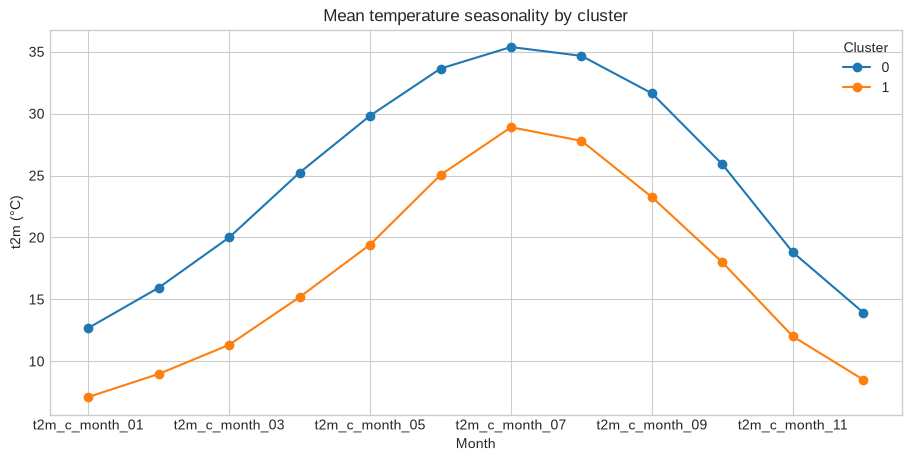

In [6]:
temperature_cols = [f"t2m_c_month_{m:02d}" for m in range(1, 13)]
precip_cols = [f"tp_mm_month_{m:02d}" for m in range(1, 13)]
cluster_means = feature_frame.groupby("cluster")[climate_cols].mean()
profile = pd.DataFrame(index=cluster_means.index)
profile["mean_annual_t2m_C"] = cluster_means[temperature_cols].mean(axis=1)
profile["seasonal_t2m_range_C"] = cluster_means[temperature_cols].max(axis=1) - cluster_means[temperature_cols].min(axis=1)
profile["mean_monthly_tp_mm"] = cluster_means[precip_cols].mean(axis=1)
profile["number_of_grid_cells"] = feature_frame.groupby("cluster").size()
display(profile.round(2))
cluster_means[temperature_cols].T.plot(marker="o", figsize=(11, 5))
plt.title("Saisonnalité de la température moyenne par cluster")
plt.xlabel("Mois"); plt.ylabel("t2m (°C)"); plt.legend(title="Cluster"); plt.show()

### Limites d'interprétation
Le regroupement dépend de K-means et de la distance euclidienne, donc la normalisation est influente et les résultats peuvent changer en modifiant les variables, la période ou K. Testez la stabilité sur différentes périodes temporelles ou blocs spatiaux avant d'utiliser les groupes dans une décision scientifique. De plus, le silhouette et la visualisation ACP sont des outils d'aide et non une preuve unique de la validité d'une classification climatique.